# 03 - Exploratory Data Analysis (EDA)

## Applied Cleaning (summary)

Previously, we applied some data cleaning to our raw data. We checked if there was any gap in both of our datasets that needed imputation, which was not the case. We also trimmed the date range to 2006–2023 for both datasets and aligned them to the same timezone and time range. We removed useless columns from our Copernicus dataset (such as `sst`, `cbh`, `t2m`, etc.) and our PVGIS dataset (`Int`). We clipped the `ssrd` so the minimum value is 0 and converted it from $J/m^2$ to $W/m^2$.

In [34]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [36]:
from src.config import PREPROCESSED_DATA_FILEROUTE
from src.visualization.plots import (
    plot_daily_profile,
    plot_daily_seasonal_profile,
    set_seasonal_profile,
)

processed_data = pd.read_csv(PREPROCESSED_DATA_FILEROUTE, sep=',', encoding='utf-8')
processed_data['time'] = pd.to_datetime(processed_data['time'], errors='coerce', utc=True)
processed_data.set_index('time', inplace=True)
processed_data.index = processed_data.index.tz_convert('Europe/Madrid')
processed_data.head()


,P,Gb(i),Gd(i),Gr(i),H_sun,T2m,WS10m,v100,v10,d2m,...,msl,skt,slhf,sp,sshf,ssrd,strd,tcc,tp,fdir
time,,,,,,,,,,,,,,,,,,,,,
2006-01-01 00:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.72,6.14,0.784286,0.346283,278.47076,...,101056.560,279.50934,-48159.0,98977.516,32718.0,0.0,1111961.20,0.983185,0.000000e+00,0.0
2006-01-01 01:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.59,7.10,-0.314621,-0.198929,278.65588,...,101037.875,280.03403,-56592.0,98955.700,65555.0,0.0,1066923.80,0.742828,4.768372e-07,0.0
2006-01-01 02:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.38,7.72,-1.158997,-0.526077,278.33942,...,101008.940,280.30255,-56844.0,98924.625,79512.0,0.0,990057.94,0.971588,4.768372e-07,0.0
2006-01-01 03:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.21,7.79,-2.188812,-1.077423,277.91210,...,101013.560,280.43246,-59865.0,98927.890,51426.0,0.0,1061742.10,0.986359,9.536743e-07,0.0
2006-01-01 04:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.03,7.79,-2.454651,-1.188324,278.11267,...,100950.560,279.63710,-59507.0,98864.330,30478.0,0.0,1112992.60,0.934662,1.478195e-05,0.0


## Daily Pattern

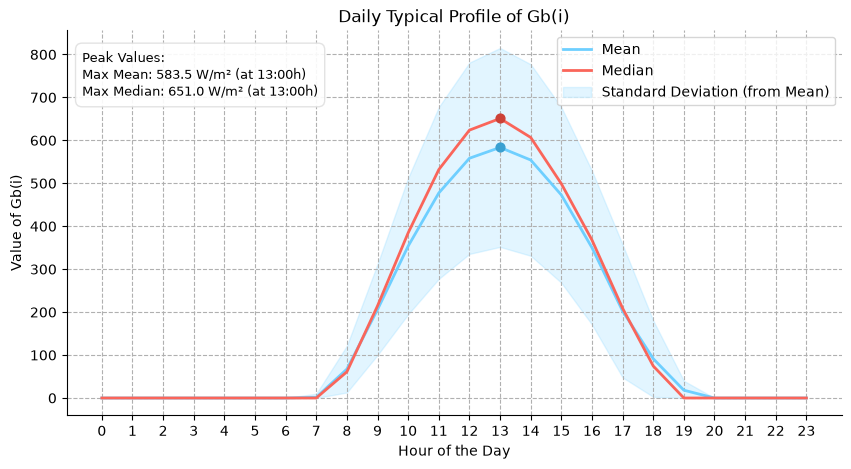

In [37]:
plot_daily_profile(processed_data, 'Gb(i)', 'Daily Typical Profile of Gb(i)', 'Hour of the Day', 'Value of Gb(i)')

## Seasonal pattern

In [38]:

seasonal_data = set_seasonal_profile(processed_data)
seasonal_data.head()

,P,Gb(i),Gd(i),Gr(i),H_sun,T2m,WS10m,v100,v10,d2m,...,skt,slhf,sp,sshf,ssrd,strd,tcc,tp,fdir,season
time,,,,,,,,,,,,,,,,,,,,,
2006-01-01 00:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.72,6.14,0.784286,0.346283,278.47076,...,279.50934,-48159.0,98977.516,32718.0,0.0,1111961.20,0.983185,0.000000e+00,0.0,Winter
2006-01-01 01:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.59,7.10,-0.314621,-0.198929,278.65588,...,280.03403,-56592.0,98955.700,65555.0,0.0,1066923.80,0.742828,4.768372e-07,0.0,Winter
2006-01-01 02:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.38,7.72,-1.158997,-0.526077,278.33942,...,280.30255,-56844.0,98924.625,79512.0,0.0,990057.94,0.971588,4.768372e-07,0.0,Winter
2006-01-01 03:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.21,7.79,-2.188812,-1.077423,277.91210,...,280.43246,-59865.0,98927.890,51426.0,0.0,1061742.10,0.986359,9.536743e-07,0.0,Winter
2006-01-01 04:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.03,7.79,-2.454651,-1.188324,278.11267,...,279.63710,-59507.0,98864.330,30478.0,0.0,1112992.60,0.934662,1.478195e-05,0.0,Winter


### Winter Pattern

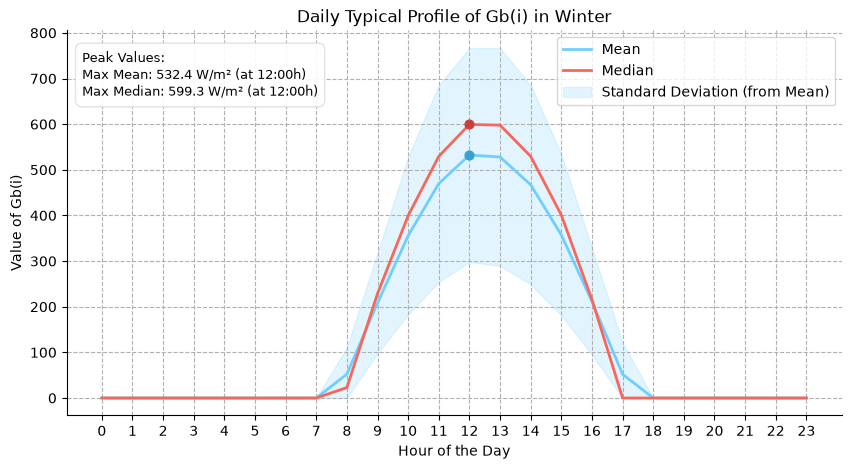

In [39]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Winter', 'Daily Typical Profile of Gb(i) in Winter', 'Hour of the Day', 'Value of Gb(i)')

### Spring Pattern

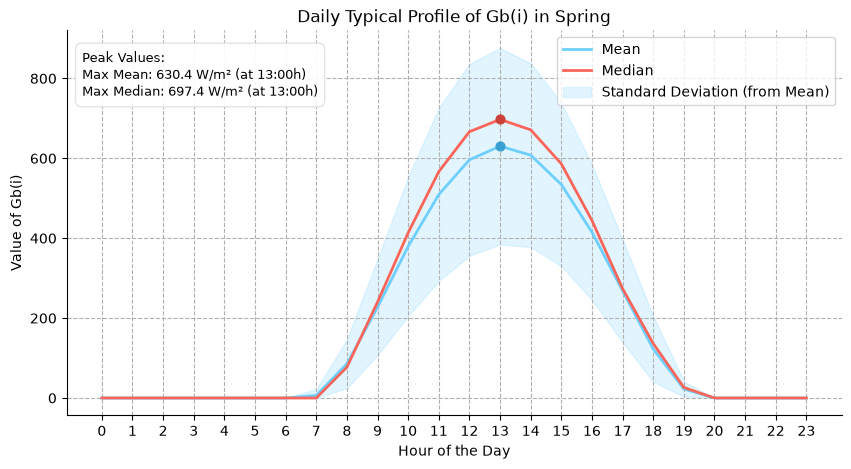

In [40]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Spring', 'Daily Typical Profile of Gb(i) in Spring', 'Hour of the Day', 'Value of Gb(i)')

### Summer Pattern

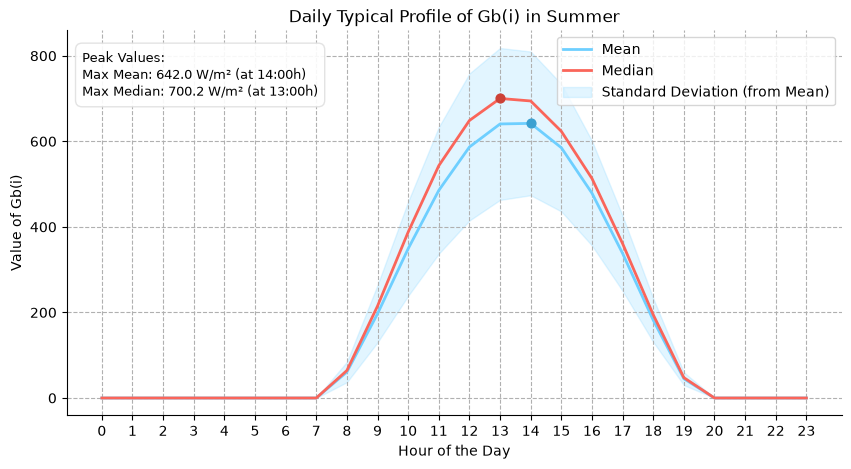

In [41]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Summer', 'Daily Typical Profile of Gb(i) in Summer', 'Hour of the Day', 'Value of Gb(i)')

### Autumn Pattern

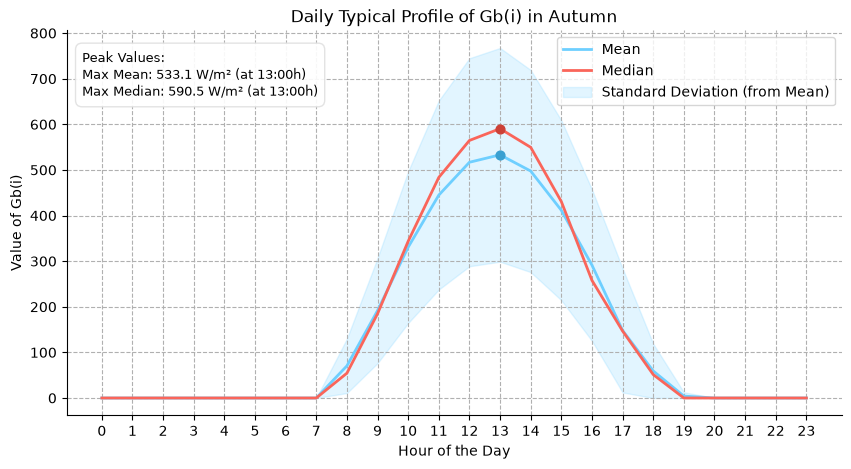

In [42]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Autumn', 'Daily Typical Profile of Gb(i) in Autumn', 'Hour of the Day', 'Value of Gb(i)')

It is observed that `Gb(i)` (filtered by the sun-grid geometry) reaches its maximum value in summer and spring but decreases in autumn and winter. The hours of peak intensity occur between 12:00 and 14:00.
It is also evident that the curve compresses during autumn and winter (as the days shorten). In winter, approximately 10 hours with positive Gb(i) values ​​are recorded, and in autumn, about 12; conversely, the curve extends in summer and spring (reaching approximately 13 hours).

## Relationship with meteorological variables

In [ ]:
# TODO: explore


## Autocorrelation


In [ ]:
# TODO: calculate and visualize (ACF)


## Conclusions
